# Etap 1: eksploracja. Ilu Polaków ma paczkomat blisko domu?

Trzy źródła:
- **paczkomaty InPost**: publiczne API mapy punktów (zrzut z dnia pobrania),
- **ludność**: Kontur Population, sześciokąty H3 o boku ok. 460 m (CC BY 4.0),
- **automaty konkurencji**: OpenStreetMap (© współtwórcy OpenStreetMap, ODbL).

Pytania: jak dobra jest jakość danych, jaki odsetek ludności ma paczkomat w zasięgu
500 m i 1 km, gdzie są białe plamy, gdzie InPost buduje nowe paczkomaty i jak wygląda konkurencja.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from paczkomaty.dane import agreguj_res8, zapisz_agregaty, zbuduj_heksagony
from paczkomaty.ludnosc import wczytaj_kontur
from paczkomaty.pokrycie import na_res9, procent_w_zasiegu

SUROWE = Path("../data/surowe")
IMG = Path("../docs/img")
IMG.mkdir(parents=True, exist_ok=True)

plik_inpost = sorted(SUROWE.glob("inpost_*[0-9].parquet"))[-1]
paczkomaty = pd.read_parquet(plik_inpost)
jakosc = json.loads(plik_inpost.with_name(plik_inpost.stem + "_jakosc.json").read_text())
konkurencja = pd.read_parquet(sorted(SUROWE.glob("osm_*.parquet"))[-1])
ludnosc8 = wczytaj_kontur(SUROWE / "kontur_population_PL_20231101.gpkg")
print("zrzut InPost:", plik_inpost.stem)

KOLOR = {"tlo": "#f2f5f7", "tekst": "#14212b", "przygaszony": "#5b6b78", "inpost": "#2a78d6",
         "budowa": "#eda100", "brak": "#d5dee5"}
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})


def mapa(ax, tytul):
    ax.set_aspect(1 / np.cos(np.radians(52)))  # przybliżona proporcja dla szerokości Polski
    ax.set_axis_off()
    ax.set_title(tytul, loc="left")

zrzut InPost: inpost_2026-10-24


## 1. Jakość danych

In [2]:
pd.Series({
    "rekordów w API": jakosc["surowych"],
    "odrzucone: poza Polską / testowe": jakosc["poza_polska"],
    "odrzucone: bez współrzędnych": jakosc["bez_wspolrzednych"],
    "duplikaty": jakosc["duplikaty"],
    "w analizie": len(paczkomaty),
}).to_frame("liczba")

,liczba
rekordów w API,34417
odrzucone: poza Polską / testowe,682
odrzucone: bez współrzędnych,0
duplikaty,0
w analizie,33735


Odrzucone punkty to nie są paczkomaty za granicą, tylko **wpisy testowe w danych InPostu**:
województwo „TEST”, „test”, „x” albo „Planowany” i współrzędne w rodzaju (0, 0) czy (11, 11).
Filtr po współrzędnych Polski wyłapał je wszystkie.

In [3]:
pd.DataFrame({
    "status": paczkomaty["status"].value_counts(),
    "udział": paczkomaty["status"].value_counts(normalize=True).round(3),
})

,status,udział
status,,
Operating,32702,0.969
Created,920,0.027
Disabled,85,0.003
NonOperating,28,0.001


In [4]:
dzialajace = paczkomaty[paczkomaty["status"] == "Operating"]
pd.Series({
    "na zewnątrz budynku": 1 - dzialajace["wewnatrz"].mean(),
    "czynne całą dobę": dzialajace["calodobowy"].mean(),
    "obsługują usługi Allegro": dzialajace["allegro"].mean(),
}).map("{:.1%}".format).to_frame("udział działających")

,udział działających
na zewnątrz budynku,89.8%
czynne całą dobę,91.2%
obsługują usługi Allegro,100.0%


**Ludność.** Kontur sumuje się do ok. 41,1 mln osób, a GUS podaje ok. 37,6 mln (2023). Zbiór powstaje
z modeli na zdjęciach satelitarnych i zawyża liczby, więc w projekcie podajemy **udziały procentowe**,
a nie liczby bezwzględne mieszkańców.

In [5]:
print(f"ludność wg Kontur: {ludnosc8['ludnosc'].sum() / 1e6:.1f} mln, sześciokątów: {len(ludnosc8):,}")

ludność wg Kontur: 41.1 mln, sześciokątów: 320,640


## 2. Ilu mieszkańców ma paczkomat w zasięgu

Ludność z sześciokątów res 8 rozkładamy równo na 7 mniejszych (res 9, bok ok. 175 m) i liczymy odległość
w linii prostej od środka każdego z nich do najbliższego **działającego** paczkomatu.
500 m to ok. 5–7 minut pieszo.

In [6]:
res9 = zbuduj_heksagony(paczkomaty, na_res9(ludnosc8))
w500 = procent_w_zasiegu(res9["ludnosc"].to_numpy(), res9["odl_m"].to_numpy(), 500)
w1km = procent_w_zasiegu(res9["ludnosc"].to_numpy(), res9["odl_m"].to_numpy(), 1000)
mediana = np.median(np.repeat(res9["odl_m"].to_numpy(), np.maximum(res9["ludnosc"].round().astype(int), 0)))
print(f"w zasięgu 500 m: {w500:.1%} | w zasięgu 1 km: {w1km:.1%} | mediana odległości mieszkańca: {mediana:.0f} m")

w zasięgu 500 m: 44.7% | w zasięgu 1 km: 67.8% | mediana odległości mieszkańca: 577 m


### Miasto a wieś

Gęstość zaludnienia sześciokąta (osób na km², res 8 ma ok. 0,74 km²) jako przybliżenie typu terenu.

In [7]:
agregaty = agreguj_res8(res9, paczkomaty, konkurencja)
POW_KM2 = 0.737
agregaty["gestosc"] = agregaty["ludnosc"] / POW_KM2
klasy = pd.cut(agregaty["gestosc"], [-1, 50, 500, 2000, np.inf],
               labels=["wieś rozproszona (<50/km²)", "wieś i przedmieścia (50–500)", "małe miasta (500–2000)", "miasta (>2000)"])
typ = agregaty.groupby(klasy, observed=True).agg(ludnosc=("ludnosc", "sum"), w500=("ludnosc_500m", "sum"), w1km=("ludnosc_1km", "sum"))
typ["udział ludności"] = typ["ludnosc"] / typ["ludnosc"].sum()
typ["w zasięgu 500 m"] = typ["w500"] / typ["ludnosc"]
typ["w zasięgu 1 km"] = typ["w1km"] / typ["ludnosc"]
typ[["udział ludności", "w zasięgu 500 m", "w zasięgu 1 km"]].style.format("{:.1%}")

,udział ludności,w zasięgu 500 m,w zasięgu 1 km
gestosc,,,
wieś rozproszona (<50/km²),5.2%,0.8%,6.9%
wieś i przedmieścia (50–500),36.2%,13.2%,36.6%
małe miasta (500–2000),27.6%,50.5%,86.1%
miasta (>2000),30.9%,83.7%,98.0%


## 3. Mapa: odległość do najbliższego paczkomatu

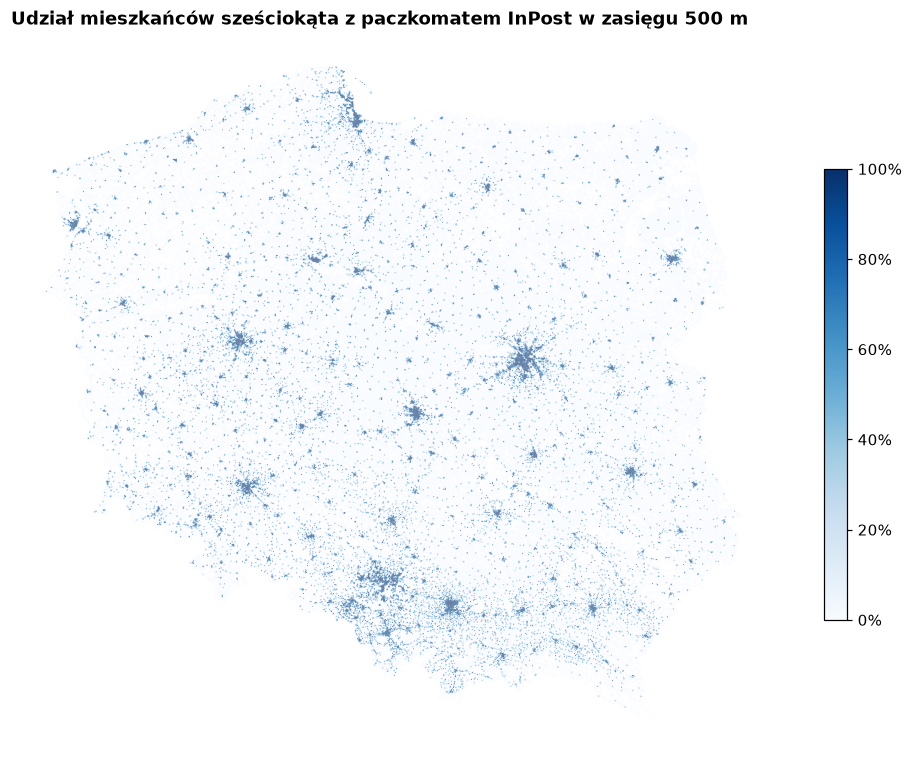

In [8]:
zasiedlone = agregaty[agregaty["ludnosc"] > 0].copy()
zasiedlone["udzial_500"] = zasiedlone["ludnosc_500m"] / zasiedlone["ludnosc"]

fig, ax = plt.subplots(figsize=(9, 8.5))
ax.scatter(zasiedlone["lon"], zasiedlone["lat"], c=zasiedlone["udzial_500"], cmap="Blues", vmin=0, vmax=1,
           s=0.35, marker="h", linewidths=0)
mapa(ax, "Udział mieszkańców sześciokąta z paczkomatem InPost w zasięgu 500 m")
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 1))
fig.colorbar(sm, ax=ax, shrink=0.5, format=lambda x, _: f"{x:.0%}")
plt.tight_layout()
fig.savefig(IMG / "pokrycie_500m.png", dpi=150, bbox_inches="tight")

## 4. Gdzie InPost buduje nowe paczkomaty

Punkty ze statusem `Created`: zarejestrowane, ale jeszcze niedziałające. To one posłużą w etapie 6
do sprawdzenia rekomendacji modelu.

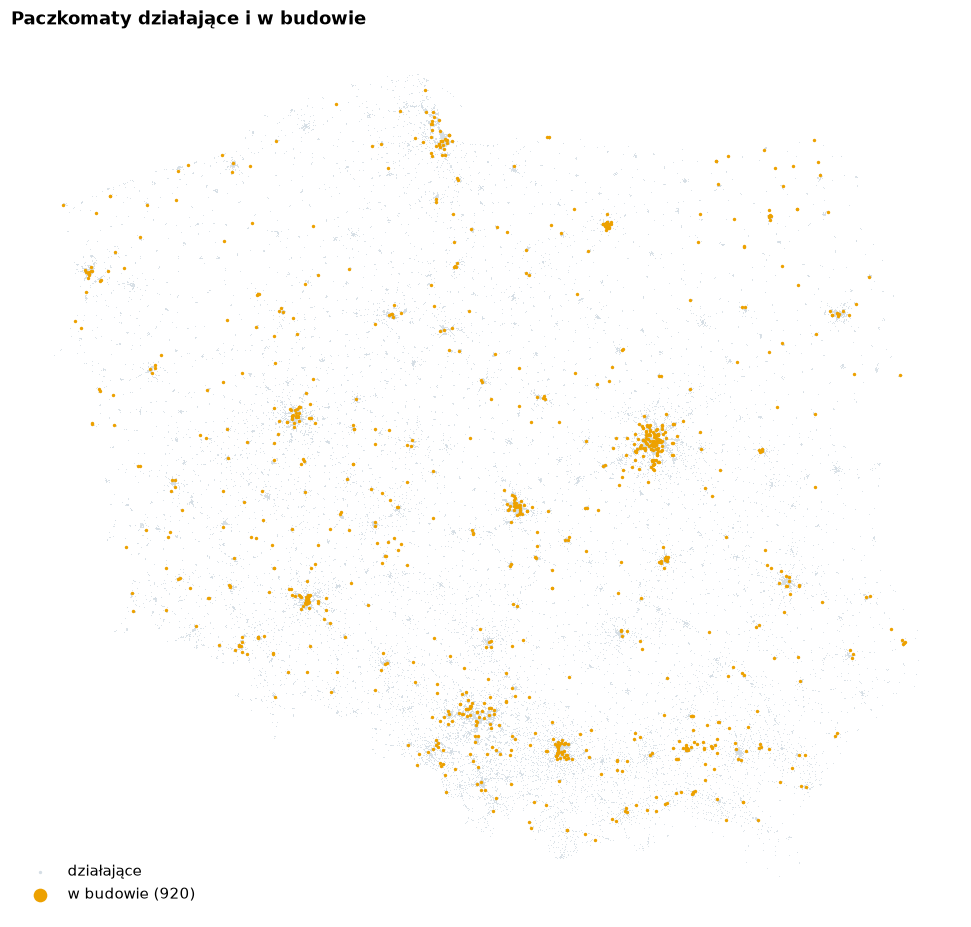

In [9]:
budowa = paczkomaty[paczkomaty["status"] == "Created"]
fig, ax = plt.subplots(figsize=(9, 8.5))
ax.scatter(dzialajace["lon"], dzialajace["lat"], s=0.3, c=KOLOR["brak"], linewidths=0, label="działające")
ax.scatter(budowa["lon"], budowa["lat"], s=5, c=KOLOR["budowa"], linewidths=0, label=f"w budowie ({len(budowa)})")
mapa(ax, "Paczkomaty działające i w budowie")
ax.legend(loc="lower left", frameon=False, markerscale=4)
plt.tight_layout()
fig.savefig(IMG / "w_budowie.png", dpi=150, bbox_inches="tight")

In [10]:
# czy nowe paczkomaty powstają tam, gdzie już jest gęsto, czy w białych plamach?
budowa_h3 = agregaty[agregaty["inpost_w_budowie"] > 0]
pd.Series({
    "nowe w sześciokątach, które już mają działający paczkomat": (budowa_h3["inpost"] > 0).mean(),
    "nowe tam, gdzie ponad połowa mieszkańców ma paczkomat ≤ 500 m": (budowa_h3["ludnosc_500m"] > budowa_h3["ludnosc"] / 2).mean(),
}).map("{:.1%}".format).to_frame("udział sześciokątów z nowymi paczkomatami")

,udział sześciokątów z nowymi paczkomatami
"nowe w sześciokątach, które już mają działający paczkomat",70.8%
"nowe tam, gdzie ponad połowa mieszkańców ma paczkomat ≤ 500 m",73.4%


## 5. Konkurencja (OpenStreetMap, dolna granica)

In [11]:
operatorzy = ["allegro_one_box", "orlen_paczka", "dpd", "dhl", "pocztex"]
nazwy = {"allegro_one_box": "Allegro One Box", "orlen_paczka": "Orlen Paczka", "dpd": "DPD", "dhl": "DHL", "pocztex": "Pocztex"}
pd.DataFrame({
    "automatów w OSM": agregaty[operatorzy].sum().rename(nazwy),
    "w sześciokątach bez InPost": agregaty.loc[agregaty["inpost"] == 0, operatorzy].sum().rename(nazwy),
}).assign(udzial=lambda d: (d["w sześciokątach bez InPost"] / d["automatów w OSM"]).map("{:.0%}".format))

,automatów w OSM,w sześciokątach bez InPost,udzial
Allegro One Box,2647,172,6%
Orlen Paczka,2289,166,7%
DPD,2390,165,7%
DHL,1943,161,8%
Pocztex,470,49,10%


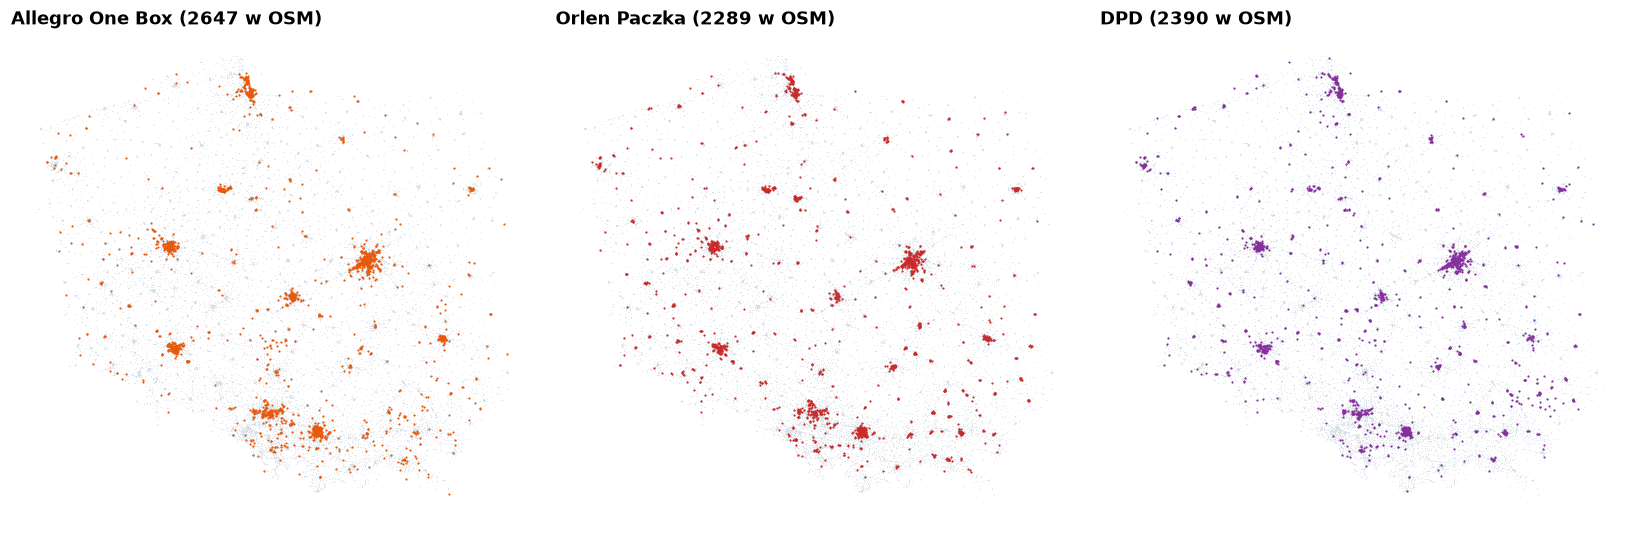

In [12]:
fig, osie = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (kolumna, kolor) in zip(osie, [("allegro_one_box", "#e8590c"), ("orlen_paczka", "#c92a2a"), ("dpd", "#862e9c")]):
    jest = agregaty[agregaty[kolumna] > 0]
    ax.scatter(dzialajace["lon"], dzialajace["lat"], s=0.2, c=KOLOR["brak"], linewidths=0)
    ax.scatter(jest["lon"], jest["lat"], s=2, c=kolor, linewidths=0)
    mapa(ax, f"{nazwy[kolumna]} ({int(jest[kolumna].sum())} w OSM)")
plt.tight_layout()
fig.savefig(IMG / "konkurencja.png", dpi=150, bbox_inches="tight")

## Wnioski z eksploracji

- **44,7% mieszkańców ma działający paczkomat InPost w zasięgu 500 m, 67,8% w zasięgu 1 km.**
  Mediana odległości mieszkańca do najbliższego paczkomatu to 577 m.
- Różnica miasto–wieś jest ogromna: w miastach (gęstość > 2000 os./km²) 83,7% ma paczkomat w 500 m,
  na wsi i przedmieściach (50–500 os./km², ponad jedna trzecia ludności) tylko 13,2%, a na wsi
  rozproszonej 0,8%. Białe plamy to przede wszystkim wieś i przedmieścia.
- **920 paczkomatów jest w budowie, a 70,8% z nich powstaje w sześciokątach, które już mają działający
  paczkomat.** InPost w tej chwili głównie zagęszcza sieć tam, gdzie już jest (najwięcej wokół Warszawy),
  zamiast wypełniać białe plamy. To ważne dla etapu 6: model szukający samych białych plam trafiłby
  w mniejszość nowych lokalizacji, więc walidacja musi to uwzględnić.
- Wszystkie działające paczkomaty obsługują usługi Allegro, więc ta cecha niczego nie różnicuje.
- Automaty konkurencji (OSM, dolna granica) stoją prawie wyłącznie tam, gdzie już jest InPost:
  tylko 6–10% z nich jest w sześciokątach bez paczkomatu InPost. Konkurencja walczy o te same
  lokalizacje w miastach, a nie o białe plamy.
- Dane mają 682 wpisy testowe (województwo „TEST”, współrzędne 0,0); odfiltrowane.

## 6. Zapis agregatów

Do aplikacji (i później do Power BI) trafiają tylko liczby na sześciokąt, bez pojedynczych punktów z API.

In [13]:
plik = zapisz_agregaty(agregaty.drop(columns=["gestosc"]), Path("../data/agregaty"))
print(plik, f"{plik.stat().st_size / 1e6:.1f} MB", len(agregaty), "sześciokątów")

../data/agregaty/heksagony_res8.parquet 8.4 MB 320640 sześciokątów
